# California Housing: ubicación e ingreso con seis clusters

Agrupamos exclusivamente `Latitude`, `Longitude` y `MedInc`, asignamos nuevos registros con el mismo K-Means y entrenamos un clasificador para reproducir esas pseudoetiquetas. No se predicen precios.

Cada fila representa un **grupo de bloques censales del censo de 1990**, no una vivienda individual: [descripción oficial de scikit-learn](https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/datasets/descr/california_housing.rst). Latitude y Longitude están en grados. `MedInc` es el ingreso mediano del grupo, expresado aproximadamente en decenas de miles de dólares de 1990 (3 ≈ 30.000 USD), según la [aclaración del autor publicada por O'Reilly](https://www.oreilly.com/catalog/errata.csp?isbn=0636920052289). El ingreso está limitado en los extremos, alrededor de 0,4999 y 15,0001; no es ingreso actual ni precio de vivienda.

Se utiliza el `housing.csv` ya descargado, sin consultar `solution.ipynb` ni descargar otro dataset. Los nombres coinciden exactamente; no se renombra ninguna columna.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'housing.csv').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from housing_workflow import FEATURES, LABELS, load_data, train_experiment, save_artifacts, predict_records
%matplotlib inline
pd.set_option('display.max_columns', 20)
raw, clean, audit = load_data()
print(json.dumps(audit, indent=2, ensure_ascii=False))
display(raw.head())

{
  "rows_before": 20640,
  "columns": [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude",
    "MedHouseVal"
  ],
  "dtypes": {
    "MedInc": "float64",
    "HouseAge": "float64",
    "AveRooms": "float64",
    "AveBedrms": "float64",
    "Population": "float64",
    "AveOccup": "float64",
    "Latitude": "float64",
    "Longitude": "float64",
    "MedHouseVal": "float64"
  },
  "nulls": {
    "MedInc": 0,
    "HouseAge": 0,
    "AveRooms": 0,
    "AveBedrms": 0,
    "Population": 0,
    "AveOccup": 0,
    "Latitude": 0,
    "Longitude": 0,
    "MedHouseVal": 0
  },
  "nonfinite_numeric": {
    "MedInc": 0,
    "HouseAge": 0,
    "AveRooms": 0,
    "AveBedrms": 0,
    "Population": 0,
    "AveOccup": 0,
    "Latitude": 0,
    "Longitude": 0,
    "MedHouseVal": 0
  },
  "full_duplicates": 0,
  "feature_duplicates": 5,
  "renamed_columns": {},
  "rows_after": 20640,
  "removed_rows": 0,
  "cleaning": "Excluir

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Auditoría y preparación

Se comprueban todas las columnas, tipos, nulos, valores no finitos y duplicados completos y en las características. Se conserva un `row_id` igual a la posición original del CSV (base cero); la configuración guarda el hash del archivo que define esa referencia. Coincidir en ubicación e ingreso no demuestra que dos grupos censales sean el mismo registro, por lo que esas coincidencias se conservan.

Solo se excluirían filas no finitas en las tres características, con conteo explícito. Aquí no hace falta eliminar ni imputar. No se recortan ingresos altos: los límites ya presentes en la fuente se documentan, sin inventar valores. Ninguna decisión de limpieza usa el precio.

,antes,después,eliminadas
0,20640,20640,0


,count,mean,std,min,25%,50%,75%,max
Latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
Longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
MedInc,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001


Ingresos en límites: 12 49


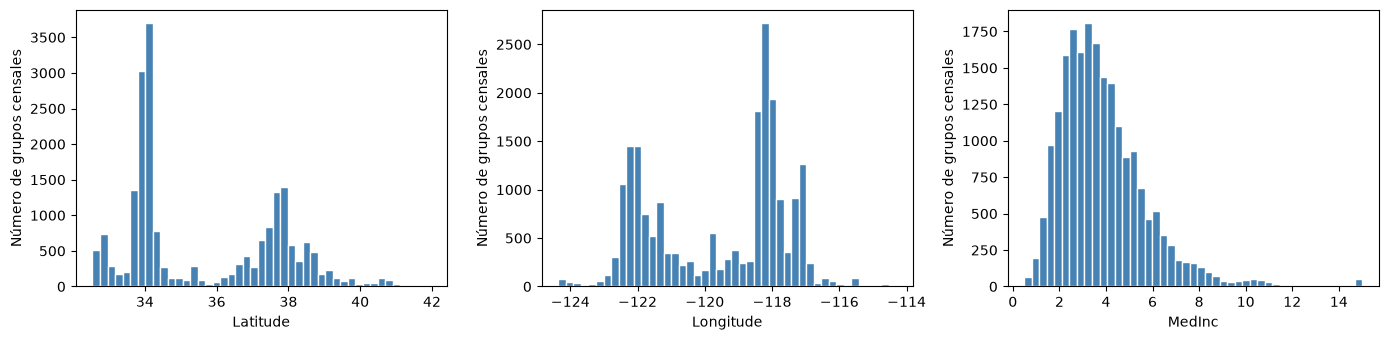

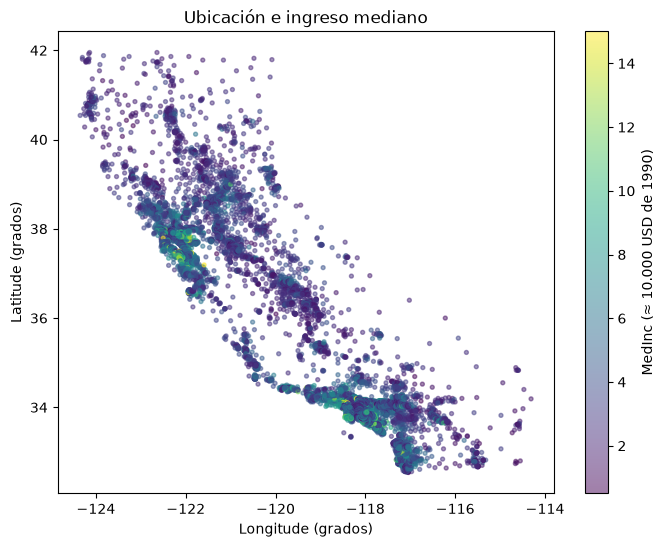

In [2]:
display(pd.DataFrame({'antes': [audit['rows_before']], 'después': [audit['rows_after']],
                      'eliminadas': [audit['removed_rows']]}))
display(clean.describe().T)
print('Ingresos en límites:', (clean.MedInc == 0.4999).sum(), (clean.MedInc == 15.0001).sum())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, FEATURES):
    ax.hist(clean[column], bins=45, color='steelblue', edgecolor='white')
    ax.set(xlabel=column, ylabel='Número de grupos censales')
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(clean.Longitude, clean.Latitude, c=clean.MedInc, cmap='viridis', s=8, alpha=0.5)
ax.set(xlabel='Longitude (grados)', ylabel='Latitude (grados)', title='Ubicación e ingreso mediano')
fig.colorbar(points, ax=ax, label='MedInc (≈ 10.000 USD de 1990)')
plt.show()

## Entrenamiento sin fuga de información

La partición aleatoria es 80/20, con `random_state=42`, antes de ajustar cualquier transformación. Cada pipeline ajusta su propio StandardScaler exclusivamente con entrenamiento. La exploración descriptiva de toda la fuente no se utiliza para elegir parámetros. K-Means utiliza `n_clusters=6`, `random_state=42`, `n_init=10`; el ejercicio fija seis grupos y no se busca otro número con el codo.

Los identificadores 0–5 son categorías enteras arbitrarias propias de este modelo, sin orden. Para el clasificador se elige de antemano regresión logística multinomial, con C=1 y sin búsqueda de hiperparámetros: las fronteras de proximidad a centroides son lineales en el espacio escalado, por lo que resulta una aproximación sencilla adecuada. La regularización y su función probabilística pueden producir desacuerdos. Se reserva test para evaluar una vez la configuración fija.

In [3]:
result = train_experiment()
train, test = result['train'], result['test']
kmeans, classifier = result['kmeans'], result['classifier']
print('Train:', len(train), 'Test:', len(test))
display(pd.DataFrame(result['metrics']['cluster_counts']).reindex(LABELS))
display(result['centers'])
summary = train.groupby('cluster')[FEATURES].agg(['count', 'mean', 'median', 'min', 'max']).reindex(LABELS)
display(summary)
print('Inercia de entrenamiento:', result['metrics']['train_inertia'])
print('Silhouette (muestra train, 2000 filas, semilla 42):', result['metrics']['train_silhouette_sample'])

Train: 16512 Test: 4128


,train,test
0,1321,337
1,3380,829
2,453,112
3,3931,962
4,2239,514
5,5188,1374


,Latitude,Longitude,MedInc
cluster,,,
0,36.082894,-119.727742,2.624008
1,33.867677,-118.024599,5.305132
2,34.893070,-119.228136,10.428292
3,38.345459,-121.900417,2.835664
4,37.702190,-121.939629,5.519572
5,33.816694,-117.816435,2.778348


Latitude                                 Longitude              \
           count       mean median    min    max     count        mean   
cluster                                                                  
0           1321  36.081628  36.30  34.38  38.51      1321 -119.727593   
1           3380  33.867888  33.92  32.56  36.36      3380 -118.024189   
2            453  34.900552  34.11  32.63  39.00       453 -119.237020   
3           3931  38.345976  38.01  36.42  41.95      3931 -121.900725   
4           2239  37.701858  37.68  35.20  40.75      2239 -121.939053   
5           5188  33.816490  33.97  32.55  36.40      5188 -117.816733   

                                MedInc                                        
         median     min     max  count       mean    median     min      max  
cluster                                                                       
0       -119.71 -121.62 -117.69   1321   2.625024   2.55560  0.4999   4.9464  
1       -118.04 -120.47 -115.39   3380   5.311771   5.10465  3.9485   8.4284  
2       -118.43 -122.56 -116.26    453  10.443602  10.12410  7.5696  15.0001  
3       -121.98 -124.35 -119.78   3931   2.835044   2.88540  0.4999   4.5590  
4       -122.02 -124.17 -118.99   2239   5.518264   5.22030  3.9792   9.5551  
5       -118.07 -119.32 -114.31   5188   2.780777   2.84750  0.4999   4.1458

Inercia de entrenamiento: 8069.187859270163
Silhouette (muestra train, 2000 filas, semilla 42): 0.40044617814902056


La inercia suma distancias cuadráticas a centroides en el espacio estandarizado; depende del tamaño y las escalas. Silhouette se estima en 2.000 filas reproducibles de entrenamiento para limitar el coste cuadrático. Resume separación y cohesión en esa geometría, puede variar con la muestra y no prueba categorías reales ni representa una validación externa.

## Asignación de test y visualización

`predict()` del pipeline fijo asigna test sin reajustar escalador ni centroides. El mapa usa una paleta categórica única para los seis grupos y marcadores distintos para train y test. Solo muestra dos de las tres dimensiones del modelo: dos puntos cercanos en el mapa pueden pertenecer a grupos distintos por su ingreso.

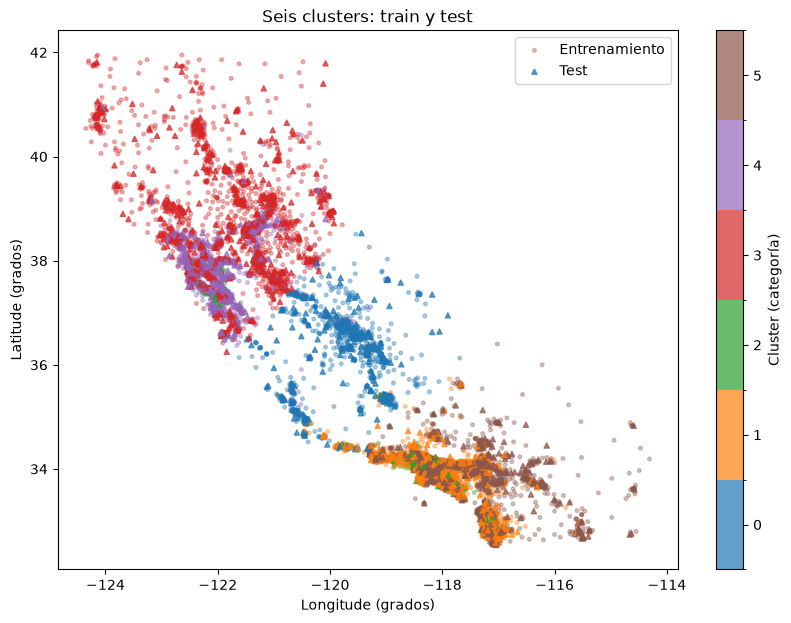

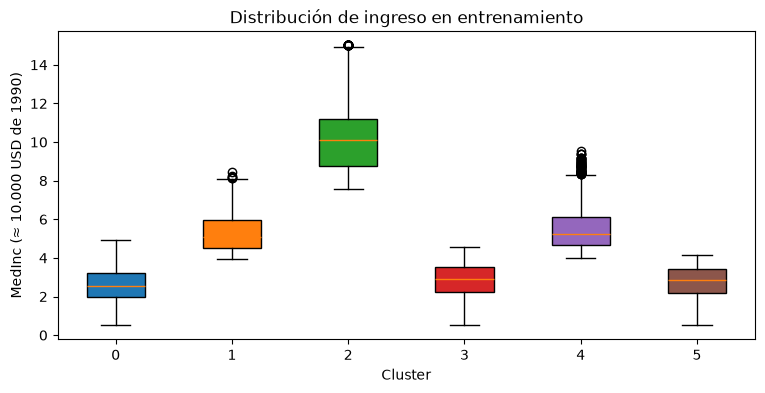

In [4]:
np.testing.assert_array_equal(test.cluster, kmeans.predict(test[FEATURES]))
palette = ListedColormap(plt.get_cmap('tab10').colors[:6])
norm = BoundaryNorm(np.arange(-0.5, 6.5), palette.N)
fig, ax = plt.subplots(figsize=(10, 7))
for frame, marker, size, alpha, label in [(train, 'o', 7, 0.35, 'Entrenamiento'),
                                         (test, '^', 14, 0.7, 'Test')]:
    points = ax.scatter(frame.Longitude, frame.Latitude, c=frame.cluster, cmap=palette,
                        norm=norm, marker=marker, s=size, alpha=alpha, label=label)
ax.set(xlabel='Longitude (grados)', ylabel='Latitude (grados)', title='Seis clusters: train y test')
ax.legend()
fig.colorbar(points, ax=ax, ticks=LABELS, label='Cluster (categoría)')
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
boxes = ax.boxplot([train.loc[train.cluster == c, 'MedInc'] for c in LABELS],
                  tick_labels=LABELS, patch_artist=True)
for patch, color in zip(boxes['boxes'], palette.colors):
    patch.set_facecolor(color)
ax.set(xlabel='Cluster', ylabel='MedInc (≈ 10.000 USD de 1990)', title='Distribución de ingreso en entrenamiento')
plt.show()

In [5]:
means = train.groupby('cluster')[FEATURES].mean()
hi, lo = means.MedInc.idxmax(), means.MedInc.idxmin()
display(Markdown(f"Los grupos combinan ingreso y posición. El grupo **{hi}** tiene el mayor ingreso medio "
                 f"({means.loc[hi, 'MedInc']:.2f}) y el grupo **{lo}** el menor ({means.loc[lo, 'MedInc']:.2f}). "
                 "El mapa presenta solapamientos entre colores; el ingreso ayuda a separar puntos de posición similar. "
                 "Las cajas también se solapan: ninguna dimensión aislada define los grupos. "
                 "No se atribuyen nombres regionales ni se considera el mapa una prueba de corrección."))

Los grupos combinan ingreso y posición. El grupo **2** tiene el mayor ingreso medio (10.44) y el grupo **0** el menor (2.63). El mapa presenta solapamientos entre colores; el ingreso ayuda a separar puntos de posición similar. Las cajas también se solapan: ninguna dimensión aislada define los grupos. No se atribuyen nombres regionales ni se considera el mapa una prueba de corrección.

## Evaluación del clasificador y desacuerdos

`y_train` son las asignaciones del K-Means entrenado y `y_test` sus predicciones fijas en test. Las entradas siguen siendo únicamente las tres variables; `cluster`, `row_id` y precio quedan fuera. Las métricas siguientes miden imitación de pseudoetiquetas, no seis categorías reales de viviendas ni predicción de precios.

Accuracy: 0.987888; F1 macro: 0.979953


,precision,recall,f1-score,support
0,0.990596,0.937685,0.963415,337.0
1,0.983333,0.996381,0.989814,829.0
2,0.981308,0.937500,0.958904,112.0
3,0.978637,1.000000,0.989203,962.0
4,0.988189,0.976654,0.982387,514.0
5,0.997082,0.994905,0.995993,1374.0


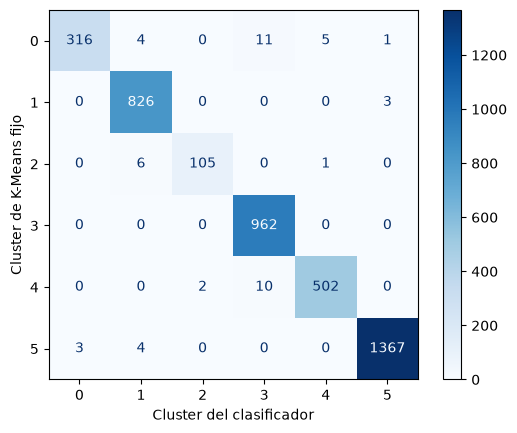

Desacuerdos: 50


,Latitude,Longitude,MedInc,cluster,classifier_prediction,distance_margin
row_id,,,,,,
15250,32.98,-117.31,4.1012,1,5,0.000251
20162,34.39,-119.34,2.4659,0,5,0.002402
9125,34.58,-118.07,4.0147,5,1,0.003803
20099,37.96,-120.24,1.6250,0,3,0.004659
13017,38.70,-121.20,4.3214,4,3,0.004747
16814,37.64,-122.43,4.1033,4,3,0.005152
17577,37.31,-121.94,4.0474,4,3,0.005516
15726,37.78,-122.45,4.1319,4,3,0.007323
20292,34.17,-119.18,3.9331,5,1,0.007382


,count,mean,median,min,max
disagreement,,,,,
False,4078,0.758096,0.788486,0.000979,2.632045
True,50,0.064499,0.033267,0.000251,0.365378


In [6]:
metrics = result['metrics']
print(f"Accuracy: {metrics['accuracy']:.6f}; F1 macro: {metrics['macro_f1']:.6f}")
report = pd.DataFrame(metrics['classification_report']).T
report.index = report.index.astype(str)
display(report.loc[[str(c) for c in LABELS]])
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']), display_labels=LABELS).plot(cmap='Blues')
plt.xlabel('Cluster del clasificador')
plt.ylabel('Cluster de K-Means fijo')
plt.show()
pred = classifier.predict(test[FEATURES])
distances = np.sort(kmeans.transform(test[FEATURES]), axis=1)
comparison = test.assign(classifier_prediction=pred,
                         distance_margin=distances[:, 1] - distances[:, 0])
disagreements = comparison.loc[comparison.cluster != comparison.classifier_prediction].sort_values('distance_margin')
print('Desacuerdos:', len(disagreements))
display(disagreements.head(10))
display(comparison.assign(disagreement=comparison.cluster != comparison.classifier_prediction)
        .groupby('disagreement').distance_margin.agg(['count', 'mean', 'median', 'min', 'max']))

El margen es la diferencia entre la segunda y la primera distancia al centroide, en unidades estandarizadas; un margen pequeño indica cercanía a una frontera, no una probabilidad ni incertidumbre calibrada. La tabla muestra casos dudosos y permite contrastar desacuerdos con coincidencias. No se cambia el clasificador tras inspeccionar test.

En esta ejecución, los 50 desacuerdos tienen margen mediano **0,0333**, frente a **0,7885** en las 4.078 coincidencias: tienden a situarse cerca de fronteras. Por ejemplo, `row_id=15250` pasa de cluster 1 en K-Means a 5 en el clasificador, con margen 0,000251; `row_id=20162` pasa de 0 a 5, con margen 0,002402. No todos los errores son casi empates (margen máximo 0,3654). Los clusters 0 y 2 tienen los menores recalls, aproximadamente 0,938; el 2 tiene solo 112 filas de test, por lo que su estimación es menos estable.

## Persistencia, nuevos registros y comprobaciones

Se guardan ambos pipelines completos con joblib, el CSV ordenado por referencia original, centroides, auditoría, métricas y configuración con versiones y SHA-256. Las comprobaciones comparan las predicciones de los modelos en memoria y recargados para **todas** las filas válidas, además de particiones disjuntas, conservación, categorías válidas y correspondencia del CSV.

In [7]:
checks = save_artifacts(result)
print(json.dumps(checks, indent=2))
# Ejemplos sintéticos de entrada, solo para demostrar la interfaz; no son datos de evaluación.
new_records = [{'Latitude': 34.05, 'Longitude': -118.25, 'MedInc': 3.5},
               {'Latitude': 37.77, 'Longitude': -122.42, 'MedInc': 7.0}]
display(predict_records(new_records))

{
  "partitions_disjoint": true,
  "rows_conserved": true,
  "labels_valid": true,
  "csv_aligned": true,
  "reload_predictions_equal": true,
  "scaler_train_only": true
}


,Latitude,Longitude,MedInc,cluster,classifier_prediction
0,34.05,-118.25,3.5,5,5
1,37.77,-122.42,7.0,4,4


In [8]:
display(Markdown(
    f"## Conclusiones basadas en esta ejecución\n\n"
    f"Se conservaron **{len(result['clean']):,}** grupos censales: {len(train):,} en train y {len(test):,} en test. "
    f"La inercia fue **{metrics['train_inertia']:.2f}** y silhouette muestral **{metrics['train_silhouette_sample']:.4f}**. "
    f"La regresión logística obtuvo **{metrics['accuracy']:.2%}** de accuracy y **{metrics['macro_f1']:.4f}** de F1 macro, "
    f"con **{metrics['test_disagreements']}** desacuerdos. "
    "La menor clase tiene menos observaciones y el F1 macro permite que su rendimiento no quede oculto por las clases grandes. "
    "La fidelidad es alta pero imperfecta; para reproducir exactamente las asignaciones se utiliza directamente el pipeline de K-Means.\n\n"
    "La distancia euclídea sobre coordenadas estandarizadas no mide kilómetros ni distancia geodésica; "
    "su ponderación depende de las dispersiones observadas y la correlación geográfica. "
    "El escalado iguala varianzas pero no garantiza importancia conceptual equivalente. "
    "La partición aleatoria no prueba generalización a otras regiones ni a otro periodo: hay dependencia espacial. "
    "Los ingresos están limitados en la fuente y los datos son de 1990. "
    "Seis clusters es una exigencia del ejercicio, sin evidencia de seis categorías naturales. "
    "Las etiquetas son arbitrarias: un reentrenamiento podría cambiar sus identificadores. "
    "El clasificador aprende decisiones del modelo fijo, no una verdad externa."
))

## Conclusiones basadas en esta ejecución

Se conservaron **20,640** grupos censales: 16,512 en train y 4,128 en test. La inercia fue **8069.19** y silhouette muestral **0.4004**. La regresión logística obtuvo **98.79%** de accuracy y **0.9800** de F1 macro, con **50** desacuerdos. La menor clase tiene menos observaciones y el F1 macro permite que su rendimiento no quede oculto por las clases grandes. La fidelidad es alta pero imperfecta; para reproducir exactamente las asignaciones se utiliza directamente el pipeline de K-Means.

La distancia euclídea sobre coordenadas estandarizadas no mide kilómetros ni distancia geodésica; su ponderación depende de las dispersiones observadas y la correlación geográfica. El escalado iguala varianzas pero no garantiza importancia conceptual equivalente. La partición aleatoria no prueba generalización a otras regiones ni a otro periodo: hay dependencia espacial. Los ingresos están limitados en la fuente y los datos son de 1990. Seis clusters es una exigencia del ejercicio, sin evidencia de seis categorías naturales. Las etiquetas son arbitrarias: un reentrenamiento podría cambiar sus identificadores. El clasificador aprende decisiones del modelo fijo, no una verdad externa.